# cv1（必修讲义）·「✍️ 练习」参考答案

> 配套 `cv1.ipynb` 的 **12 组练习**。**先自己写一遍，再来对**——直接看答案学不到东西。
>
> **怎么用**：每一章先是「思路 / 结论」，后面是**能直接跑的代码**，
> 输出就是我在自己机器上跑出来的真实结果（图也留在里面了）。
> 你可以改参数、换图片，直接看结果怎么变。
>
> **实测环境**：`opencv-contrib-python 5.0.0.93` + `numpy 2.4.6`
> （`cv1.ipynb` 里保存的输出是在 **OpenCV 4.13.0** 上跑的；本文件用到的 API 两版行为一致）。
>
> ⚠️ **数字只是参考**：换一张图、换一组阈值，数就会变。重点看「怎么想、怎么试、错了先查什么」。

In [1]:
# ===== 起手式：和讲义一致 =====
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 中文字体（Windows 用雅黑，Linux 可换成 WenQuanYi / Noto）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'WenQuanYi Micro Hei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 68
print('OpenCV', cv2.__version__, '| numpy', np.__version__)

OpenCV 5.0.0 | numpy 2.4.6


---
# 第 1 章 图像的读取与显示

**练习 1（三种模式）**：`IMREAD_COLOR` 得到 3 通道；`IMREAD_GRAYSCALE` 少一个维度；
`IMREAD_UNCHANGED` **文件里有什么就给什么**——`nl_think.png` 本来就没 alpha，所以还是 3 通道。

**练习 2（缩到宽 500）**：`cv2.resize` 的 `dsize` 是 **`(宽, 高)`**，和 `img.shape` 反过来写。

**练习 3（PNG vs JPEG q30）**：JPEG 小 20 倍左右，代价是有损。**中间结果存 PNG**。

**练习 4（视频）**：`CAP_PROP_FPS` / `CAP_PROP_FRAME_COUNT`，
时长 = 帧数 / 帧率。

**练习 5（抽帧拼长图）**：每 10 帧取一帧；60 帧横拼出来 7 万多像素宽，**要看的话先缩每帧**。

**自测**：图像处理 = 数组运算，因为 OpenCV-Python 里**图像就是 `numpy.ndarray`**。

=== 1.1 三种读取模式 ===
IMREAD_COLOR       shape=(655, 690, 3)   dtype=uint8 size=1355850
IMREAD_GRAYSCALE   shape=(655, 690)      dtype=uint8 size=451950
IMREAD_UNCHANGED   shape=(655, 690, 3)   dtype=uint8 size=1355850

=== 1.2 缩到宽 500 ===
(1080, 1920, 3) -> (281, 500, 3)   (dsize 是 (宽, 高)！)

=== 1.3 PNG vs JPEG(q30) ===
PNG        244806 B
JPEG q30    12354 B   (0.05 倍)
平均绝对像素差 2.56  <- 有损的代价

=== 1.4 视频帧率 / 总帧数 / 时长 ===
fps=25.0  帧数=596  时长=23.84 秒

=== 1.5 每 10 帧抽一帧 ===
抽到 60 帧，单帧 (720, 1280, 3)，横拼后 76800x720


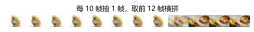

In [2]:
print('=== 1.1 三种读取模式 ===')
for name, flag in [('IMREAD_COLOR', cv2.IMREAD_COLOR),
                   ('IMREAD_GRAYSCALE', cv2.IMREAD_GRAYSCALE),
                   ('IMREAD_UNCHANGED', cv2.IMREAD_UNCHANGED)]:
    a = cv2.imread('res/nl_think.png', flag)
    print(f'{name:18s} shape={str(a.shape):15s} dtype={a.dtype} size={a.size}')

print()
print('=== 1.2 缩到宽 500 ===')
img = cv2.imread('res/nl_hd13.jpg')
h, w = img.shape[:2]
small = cv2.resize(img, (500, int(h * 500 / w)))
print(f'{img.shape} -> {small.shape}   (dsize 是 (宽, 高)！)')

print()
print('=== 1.3 PNG vs JPEG(q30) ===')
s = cv2.imread('res/nl_santa.png')


def size_of(im, ext, params=()):
    ok, buf = cv2.imencode(ext, im, list(params))
    return len(buf.tobytes())


png_b = size_of(s, '.png')
jpg_b = size_of(s, '.jpg', [cv2.IMWRITE_JPEG_QUALITY, 30])
_, jb = cv2.imencode('.jpg', s, [cv2.IMWRITE_JPEG_QUALITY, 30])
s2 = cv2.imdecode(jb, cv2.IMREAD_COLOR)
print(f'PNG      {png_b:8d} B')
print(f'JPEG q30 {jpg_b:8d} B   ({jpg_b/png_b:.2f} 倍)')
print(f'平均绝对像素差 {abs(s.astype(int)-s2.astype(int)).mean():.2f}  <- 有损的代价')

print()
print('=== 1.4 视频帧率 / 总帧数 / 时长 ===')
cap = cv2.VideoCapture('res/nl_video.mp4')
fps = cap.get(cv2.CAP_PROP_FPS)
n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f'fps={fps}  帧数={n}  时长={n/fps:.2f} 秒')

print()
print('=== 1.5 每 10 帧抽一帧 ===')
frames, i = [], 0
while True:
    ok, f = cap.read()
    if not ok:
        break
    if i % 10 == 0:
        frames.append(f)
    i += 1
cap.release()
print(f'抽到 {len(frames)} 帧，单帧 {frames[0].shape}，'
      f'横拼后 {sum(f.shape[1] for f in frames)}x{frames[0].shape[0]}')

# 拼一小段看看（全拼太宽看不清）
strip = cv2.hconcat([cv2.resize(f, (160, 90)) for f in frames[:12]])
show_img(strip, titles=[f'每 10 帧抽 1 帧，取前 12 帧横拼'])

---
# 第 2 章 图像的基本操作

**练习 1**：先 `print(img.shape)` 再写坐标——`shape` 是 `(高, 宽, 通道)`，
x 最大到 667、y 最大到 689，写超了直接 `IndexError`。

**练习 2**：`q[:h//2]` 是**视图不是副本**，必须 `.copy()`，否则改"上半"就是改原图。

**练习 3**：`copyMakeBorder` 的 `value` 是 **BGR**——`(255,0,0)` 是**蓝色**边框。

**练习 4**：取中心 1/4，像素数减少 **75%**。这就是 ROI「性价比最高」的原因：
  计算量按面积降，还顺手排除了画面外的干扰。

**练习 5**：`cv2.split(img)[i]` 和 `img[:, :, i]` **数值完全相同**；
  区别是前者**复制**（慢）、后者是**视图**（快）。只取一个通道时用切片。

**自测**：ROI 同时买到三件事——计算量下降、干扰被排除、不用改算法/调参。

=== 2.1 打印像素，找背景与主体 ===
shape (690, 668, 3)
  角落(背景)       (5,5) BGR=[255, 255, 255]
  中心(主体)       (334,345) BGR=[94, 196, 225]

=== 2.2 上半部分覆盖到下半部分（注意 .copy()） ===
原图 (864, 824, 3) -> 上/下 (432, 824, 3)

=== 2.3 补 30 像素白边 ===
(302, 320, 3) -> (362, 380, 3)  (value 是 BGR，(0,0,255) 才是红框)

=== 2.4 取中心 1/4 ===
原图 6220800 像素  ROI 1555200 像素  减少 75.0%

=== 2.5 split 与切片是否相同 ===
np.array_equal(cv2.split(img)[2], img[:,:,2]) = True


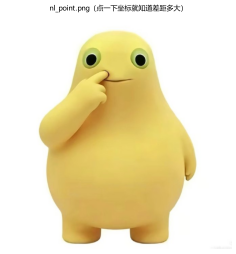

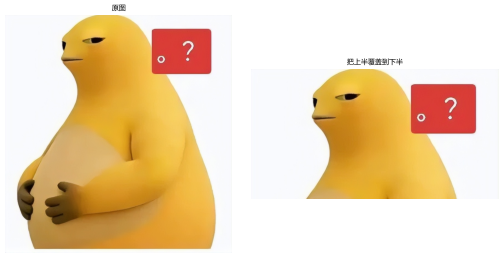

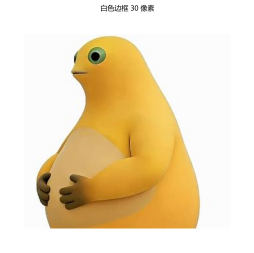

In [3]:
print('=== 2.1 打印像素，找背景与主体 ===')
pt = cv2.imread('res/nl_point.png')
print('shape', pt.shape)
for tag, (x, y) in [('角落(背景)', (5, 5)), ('中心(主体)', (pt.shape[1]//2, pt.shape[0]//2))]:
    print(f'  {tag:12s} ({x},{y}) BGR={pt[y, x].tolist()}')
show_img(pt, titles=['nl_point.png（点一下坐标就知道差距多大）'])

print()
print('=== 2.2 上半部分覆盖到下半部分（注意 .copy()） ===')
q = cv2.imread('res/nl_question.png')
h = q.shape[0]
up = q[:h//2].copy()
dn = q[h//2:].copy()
dn[:up.shape[0]] = up[:dn.shape[0]]
print(f'原图 {q.shape} -> 上/下 {up.shape}')
show_img(q, dn, titles=['原图', '把上半覆盖到下半'])

print()
print('=== 2.3 补 30 像素白边 ===')
side = cv2.imread('res/nl_side.png')
b = cv2.copyMakeBorder(side, 30, 30, 30, 30, cv2.BORDER_CONSTANT, value=(255, 255, 255))
print(f'{side.shape} -> {b.shape}  (value 是 BGR，(0,0,255) 才是红框)')
show_img(b, titles=['白色边框 30 像素'])

print()
print('=== 2.4 取中心 1/4 ===')
img = cv2.imread('res/nl_hd17.jpg')
H, W = img.shape[:2]
roi = img[H//4:H*3//4, W//4:W*3//4]
print(f'原图 {img.size} 像素  ROI {roi.size} 像素  减少 {100*(1-roi.size/img.size):.1f}%')

print()
print('=== 2.5 split 与切片是否相同 ===')
print('np.array_equal(cv2.split(img)[2], img[:,:,2]) =',
      np.array_equal(cv2.split(img)[2], img[:, :, 2]))

---
# 第 3 章 颜色空间

**练习 1**：**红帽子的 H 是 `0~14` 与 `243~255`（跨 0 点，必须分两段）**——
  实测红色区的 H 取值只落在两端。
  ⚠️ 顺便注意：**白色的 H 是随机的、没有意义**（S≈0 时 H 没有定义），
  判断"是不是白"要看 **S 和 V**。

**练习 2**：橙 `BGR(0,140,255)` → HSV_FULL `[23,255,255]`；紫 `BGR(200,0,140)` → `[201,255,200]`，
  和讲义的颜色区间表对得上。

**练习 3**：星空图的 H/S/V 范围都很大（本来就什么都有一点），**要看均值**：
  S 平均只有 60 → 大部分像素是**灰的**，颜色信息很弱。所以暗图别靠 H 分割。

**练习 4**：HSV 最大 179、HSV_FULL 最大 255，比值 **1.425**（讲义写 ≈1.417，差在取整）。

**练习 5**：**`YCrCb` 的 `Y` 通道和 `BGR2GRAY` 完全相同**（差值 0.00），因为它就是那个加权亮度公式。

**练习 6**：色相 90° → HSV `45`、HSV_FULL `64`（`90/2`、`90×255/360`）。

**练习 7**：`HSV.png` 默认读 3 通道、`UNCHANGED` 读 4 通道，但 **alpha 全是 255**（完全不透明），
  所以看不出差别。

**练习 8**：渐变 alpha 的混合结果**落在前景和底图之间**，这就是"真透明"；
  注意 alpha 要广播成 `(1, 宽, 1)`，全程 `float32`。

**练习 9**：`float` 图（0~1 刻度）直接 `imwrite` → **几乎全黑**（均值 1.40）；
  先 `clip → ×255 → uint8` 才对（均值 237）。

**练习 10（思考）**：结果一样，但 `imread(..., 0)` **读的时候就转**，省一次全图转换 + 一份彩色内存。

=== 3.1 nl_santa 的采样与红帽 H 范围 ===
  红帽子   (200,40) BGR=[20, 27, 176]  HSV_FULL=[2, 226, 176]
  白毛边   (150,75) BGR=[238, 240, 240]  HSV_FULL=[43, 2, 240]
  黄脸    (210,150) BGR=[56, 135, 192]  HSV_FULL=[25, 181, 192]
  白背景   (470,470) BGR=[243, 245, 246]  HSV_FULL=[28, 3, 246]
  红色像素 80693 个，占 32.4%
  红色区的 H 只落在两端: [0, 1, 2, 3, 4, 5] ... [250, 251, 252, 253, 254, 255]
  ↑ 这就是"红色必须分两段"的原因
  ⚠️ 白色的 S≈2~3，但它的 H 是 43/28 —— 白的 H 没有意义，别用 H 判白

=== 3.2 橙 / 紫 的 HSV_FULL ===
  橙 BGR=[0, 140, 255] -> HSV_FULL=[23, 255, 255]
  紫 BGR=[200, 0, 140] -> HSV_FULL=[201, 255, 200]

=== 3.3 nl_galaxy（星空暗图）===
  H 0~252  S 0~255  V 0~255
  均值 H=148.0 S=59.9 V=150.1
  ↑ 范围没意义，要看均值：S 平均只有 60 -> 大部分像素是灰的，颜色信息弱

=== 3.4 验证 ×1.417 ===
  HSV Hmax=179  HSV_FULL Hmax=255  比值=1.425

=== 3.5 Lab / YCrCb 哪个通道最像灰度 ===
  YCrCb.Y   与 BGR2GRAY 的平均绝对差 =   0.00
  Lab.L     与 BGR2GRAY 的平均绝对差 =   9.26
  YCrCb.Cb  与 BGR2GRAY 的平均绝对差 =  81.51
  YCrCb.Cr  与 BGR2GRAY 的平均绝对差 = 104.58
  ↑ YCrCb.Y 的差是 0.00 —— 它就是那个加权亮度公式

=== 3.6 色相 9

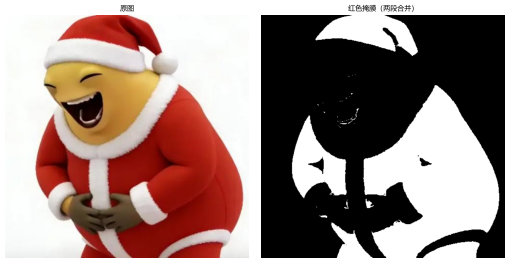

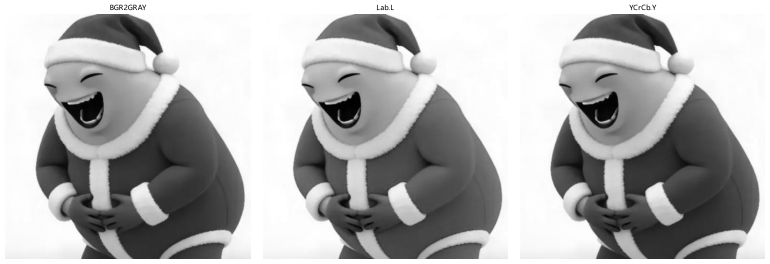

In [4]:
print('=== 3.1 nl_santa 的采样与红帽 H 范围 ===')
san = cv2.imread('res/nl_santa.png')
hsv = cv2.cvtColor(san, cv2.COLOR_BGR2HSV_FULL)
for tag, (x, y) in [('红帽子', (200, 40)), ('白毛边', (150, 75)),
                    ('黄脸', (210, 150)), ('白背景', (470, 470))]:
    print(f'  {tag:5s} ({x},{y}) BGR={san[y,x].tolist()}  HSV_FULL={hsv[y,x].tolist()}')
hch = hsv[:, :, 0]
red = ((hch <= 14) | (hch >= 243)) & (hsv[:, :, 1] > 80) & (hsv[:, :, 2] > 80)
print(f'  红色像素 {int(red.sum())} 个，占 {100*red.sum()/red.size:.1f}%')
print(f'  红色区的 H 只落在两端: {sorted(set(hch[red].tolist()))[:6]} ... {sorted(set(hch[red].tolist()))[-6:]}')
print('  ↑ 这就是"红色必须分两段"的原因')
print('  ⚠️ 白色的 S≈2~3，但它的 H 是 43/28 —— 白的 H 没有意义，别用 H 判白')
show_img(san, cv2.cvtColor(red.astype(np.uint8) * 255, cv2.COLOR_GRAY2BGR),
         titles=['原图', '红色掩膜（两段合并）'])

print()
print('=== 3.2 橙 / 紫 的 HSV_FULL ===')
for name, bgr in [('橙', (0, 140, 255)), ('紫', (200, 0, 140))]:
    a = np.uint8([[list(bgr)]])
    print(f'  {name} BGR={list(bgr)} -> HSV_FULL={cv2.cvtColor(a, cv2.COLOR_BGR2HSV_FULL)[0,0].tolist()}')

print()
print('=== 3.3 nl_galaxy（星空暗图）===')
gal = cv2.imread('res/nl_galaxy.png')
hg = cv2.cvtColor(gal, cv2.COLOR_BGR2HSV_FULL)
print(f'  H {int(hg[:,:,0].min())}~{int(hg[:,:,0].max())}  '
      f'S {int(hg[:,:,1].min())}~{int(hg[:,:,1].max())}  '
      f'V {int(hg[:,:,2].min())}~{int(hg[:,:,2].max())}')
print(f'  均值 H={hg[:,:,0].mean():.1f} S={hg[:,:,1].mean():.1f} V={hg[:,:,2].mean():.1f}')
print('  ↑ 范围没意义，要看均值：S 平均只有 60 -> 大部分像素是灰的，颜色信息弱')

print()
print('=== 3.4 验证 ×1.417 ===')
a179 = cv2.cvtColor(san, cv2.COLOR_BGR2HSV)
a255 = cv2.cvtColor(san, cv2.COLOR_BGR2HSV_FULL)
print(f'  HSV Hmax={int(a179[:,:,0].max())}  HSV_FULL Hmax={int(a255[:,:,0].max())}  '
      f'比值={a255[:,:,0].max()/max(a179[:,:,0].max(),1):.3f}')

print()
print('=== 3.5 Lab / YCrCb 哪个通道最像灰度 ===')
lab = cv2.cvtColor(san, cv2.COLOR_BGR2LAB)
ycc = cv2.cvtColor(san, cv2.COLOR_BGR2YCrCb)
gray = cv2.cvtColor(san, cv2.COLOR_BGR2GRAY)
for name, ch in [('YCrCb.Y', ycc[:, :, 0]), ('Lab.L', lab[:, :, 0]),
                 ('YCrCb.Cb', ycc[:, :, 2]), ('YCrCb.Cr', ycc[:, :, 1])]:
    print(f'  {name:9s} 与 BGR2GRAY 的平均绝对差 = '
          f'{np.abs(ch.astype(int)-gray.astype(int)).mean():6.2f}')
print('  ↑ YCrCb.Y 的差是 0.00 —— 它就是那个加权亮度公式')
show_img(gray, lab[:, :, 0], ycc[:, :, 0], titles=['BGR2GRAY', 'Lab.L', 'YCrCb.Y'])

print()
print('=== 3.6 色相 90 度 ===')
print(f'  HSV={round(90/2)}   HSV_FULL={round(90*255/360)}')

=== 3.7 res/HSV.png 的两种读法 ===
  默认        (1519, 2699, 3)
  UNCHANGED   (1519, 2699, 4)
  alpha 的 min/max = 255/255  <-全是 255（完全不透明），所以看不出画面差别

=== 3.8 用 np.linspace 造渐变 alpha ===
  加权混合均值=196.5   直接丢 alpha 均值=217.0   底图均值=174.0
  ↑ 混合结果落在两者之间 —— 左边完全等于底图、右边完全等于前景，这才是"真透明"

=== 3.9 float32 提亮后：直接存 vs 先转 uint8 ===
  ① 直接存 float 读回来的均值 =    1.40  <- 几乎全黑
  ② 先 clip*255 转 uint8 均值 =  237.24
  原图均值 = 215.7（② 比它亮，因为确实提亮了 1.5 倍）


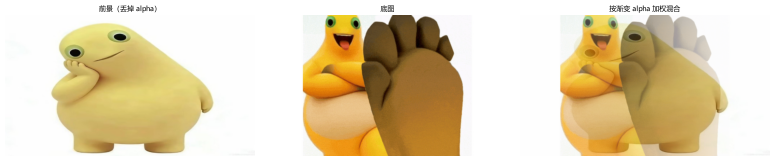

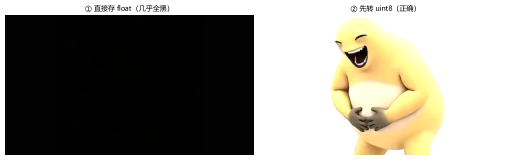

In [5]:
print('=== 3.7 res/HSV.png 的两种读法 ===')
d1 = cv2.imread('res/HSV.png')
d2 = cv2.imread('res/HSV.png', cv2.IMREAD_UNCHANGED)
print(f'  默认        {d1.shape}')
print(f'  UNCHANGED   {d2.shape}')
print(f'  alpha 的 min/max = {int(d2[:,:,3].min())}/{int(d2[:,:,3].max())}'
      f'  <-全是 255（完全不透明），所以看不出画面差别')

print()
print('=== 3.8 用 np.linspace 造渐变 alpha ===')
th = cv2.resize(cv2.imread('res/nl_think.png'), (1920, 1080))
bg = cv2.imread('res/nl_hd17.jpg')
alpha = np.linspace(0, 1, 1920, dtype=np.float32)[None, :, None]      # (1,1920,1)
blend = (th.astype(np.float32) * alpha + bg.astype(np.float32) * (1 - alpha)).astype(np.uint8)
print(f'  加权混合均值={blend.mean():.1f}   直接丢 alpha 均值={th.mean():.1f}   底图均值={bg.mean():.1f}')
print('  ↑ 混合结果落在两者之间 —— 左边完全等于底图、右边完全等于前景，这才是"真透明"')
show_img(th, bg, blend, titles=['前景（丢掉 alpha）', '底图', '按渐变 alpha 加权混合'])

print()
print('=== 3.9 float32 提亮后：直接存 vs 先转 uint8 ===')
hd = cv2.imread('res/nl_hd01.jpg')
f = (hd.astype(np.float32) / 255.0) * 1.5          # 0~1 刻度，提亮 1.5 倍
_, b_direct = cv2.imencode('.png', f)              # ① 直接存（OpenCV 会降级，并打警告）
u = np.clip(f * 255, 0, 255).astype(np.uint8)
_, b_ok = cv2.imencode('.png', u)                  # ② 先转回 0~255 的 uint8
print(f'  ① 直接存 float 读回来的均值 = {cv2.imdecode(b_direct, cv2.IMREAD_COLOR).mean():7.2f}  <- 几乎全黑')
print(f'  ② 先 clip*255 转 uint8 均值 = {cv2.imdecode(b_ok, cv2.IMREAD_COLOR).mean():7.2f}')
print(f'  原图均值 = {hd.mean():.1f}（② 比它亮，因为确实提亮了 1.5 倍）')
show_img(cv2.imdecode(b_direct, cv2.IMREAD_COLOR), cv2.imdecode(b_ok, cv2.IMREAD_COLOR),
         titles=['① 直接存 float（几乎全黑）', '② 先转 uint8（正确）'])

---
# 第 4 章 掩码与逻辑运算

**练习 1**：`cv2.add(200, 100)` = **255（饱和）**；`x + y` = **44（回绕）**。
  **图像相加永远用 `cv2.add`**，用 `+` 会让亮的地方变黑斑。

**练习 2**：`cv2.addWeighted(src1, α, src2, β, γ)` 算 `α·src1 + β·src2 + γ`，**自动饱和**。
  两个权重不要求和为 1。

**练习 3**：`bitwise_not` 做底片，均值 162.6 → 92.4。

**练习 4**：**会**。演示 3 拿走的是"落在文字笔画上的像素"，跟底下垫什么图无关；
  只要把底图 `resize` 到和文字图同尺寸即可。

**练习 5**：只留 ② 去掉 ③④ → 图上只剩**笔画那一块的反色，别处全黑**。
  因为 ③ 的作用正是把"其余原样"补回来。

**练习 6（思考）**：`bitwise_and(src1, src2, mask=)` 里 `src1/src2` 都是必填位。
  `and(img, img, mask=m)` 就是"img 与自己与（= 原样），只在 m 非零处保留"。

=== 4.1 cv2.add 与 + ===
  cv2.add(x, y) = [[255, 255]]   <- 饱和，卡在 255
  x + y         = [[44, 44]]   <- 回绕，300-256=44，dtype 还是 uint8
  ↑ 图像相加永远用 cv2.add

=== 4.2 两种比例的混合 ===
  0.5/0.5 均值=194.8   0.8/0.2 均值=207.3

=== 4.3 bitwise_not 做底片 ===
  均值 162.6 -> 92.4

=== 4.4 把演示 3 的 lena 换成 nl_hd01（缩到 512x512）===
  结论：那行字同样会变成底片色 —— 演示 3 取的是"落在笔画上的像素"，与垫图无关

=== 4.5 只留 ②，去掉 ③ 和 ④ ===
  结果：只有笔画那一块有内容，别处全黑
  原因：③ 的作用正是把"其余部分原样"补回来，去掉它就只剩笔画


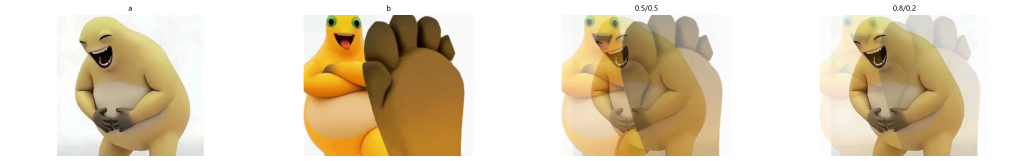

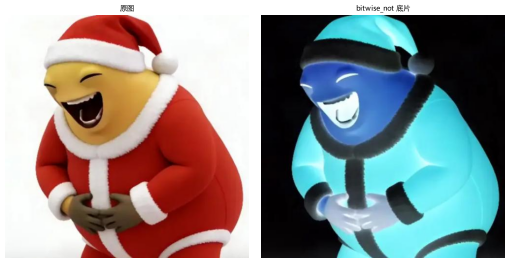

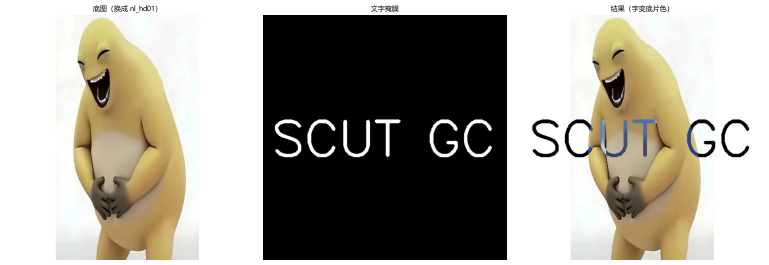

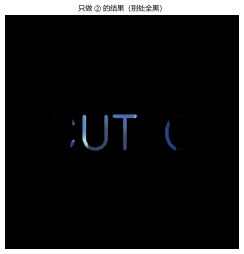

In [6]:
print('=== 4.1 cv2.add 与 + ===')
x = np.array([[200, 200]], np.uint8)
y = np.array([[100, 100]], np.uint8)
print(f'  cv2.add(x, y) = {cv2.add(x, y).tolist()}   <- 饱和，卡在 255')
print(f'  x + y         = {(x + y).tolist()}   <- 回绕，300-256=44，dtype 还是 {(x+y).dtype}')
print('  ↑ 图像相加永远用 cv2.add')

print()
print('=== 4.2 两种比例的混合 ===')
a = cv2.imread('res/nl_hd01.jpg')
b = cv2.imread('res/nl_hd17.jpg')
m1 = cv2.addWeighted(a, 0.5, b, 0.5, 0)
m2 = cv2.addWeighted(a, 0.8, b, 0.2, 0)
print(f'  0.5/0.5 均值={m1.mean():.1f}   0.8/0.2 均值={m2.mean():.1f}')
show_img(a, b, m1, m2, titles=['a', 'b', '0.5/0.5', '0.8/0.2'])

print()
print('=== 4.3 bitwise_not 做底片 ===')
san = cv2.imread('res/nl_santa.png')
inv = cv2.bitwise_not(san)
print(f'  均值 {san.mean():.1f} -> {inv.mean():.1f}')
show_img(san, inv, titles=['原图', 'bitwise_not 底片'])

print()
print('=== 4.4 把演示 3 的 lena 换成 nl_hd01（缩到 512x512）===')
big = cv2.resize(cv2.imread('res/nl_hd01.jpg'), (512, 512))
mark = cv2.imread('res/mark_white.png', cv2.IMREAD_GRAYSCALE)
mark = cv2.resize(mark, (512, 512))
mask = cv2.threshold(mark, 127, 255, cv2.THRESH_BINARY)[1]
# 算法和演示 3 一样：笔画处取反，其余原样
step2 = cv2.bitwise_not(big, mask=mask)                 # ② 笔画处反色
step3 = cv2.bitwise_and(big, big, mask=cv2.bitwise_not(mask))   # ③ 其余原样
result = cv2.add(step2, step3)                          # ④ 相加
print('  结论：那行字同样会变成底片色 —— 演示 3 取的是"落在笔画上的像素"，与垫图无关')
show_img(big, mask, result, titles=['底图（换成 nl_hd01）', '文字掩膜', '结果（字变底片色）'])

print()
print('=== 4.5 只留 ②，去掉 ③ 和 ④ ===')
only2 = cv2.bitwise_not(big, mask=mask)
print('  结果：只有笔画那一块有内容，别处全黑')
print('  原因：③ 的作用正是把"其余部分原样"补回来，去掉它就只剩笔画')
show_img(only2, titles=['只做 ② 的结果（别处全黑）'])

---
# 第 5 章 二值化与颜色分割

**练习 1**：只有 `BINARY` / `BINARY_INV` 输出真正的 **0/255 二值图**；
  `TRUNC` / `TOZERO` 的**取值里根本没有 255**，对它们算"白像素占比"没有意义。
  白底图抠目标用 **`BINARY_INV`**。

**练习 2**：换成 `BINARY` 后**黑白完全对调**：得到的是"背景"的掩膜，抠出来主体反而没了。

**练习 3**：`OTSU = 152`，`bg_threshold = 232`（灰度中位数 183）。
  **白底抠图用 `bg_threshold`** —— 阈值必须落在"目标"和"背景"之间的空档（≈230）。
  OTSU 失效是因为白底占了 60% 以上，直方图是偏态的，不满足"双峰且两峰相当"。

**练习 4**：`blockSize` 越大越接近全局阈值；`C` 越大判黑越苛刻。
  这张图整体偏亮，光靠一个 `blockSize` 通吃不了 —— **要配合 ROI**。
  ⚠️ 调参时要**看掩膜图**，不能只看占比数字。

**练习 5**：`blockSize` 取偶数直接报
  `(-215:Assertion failed) blockSize % 2 == 1 && blockSize > 1` ——
  偶数边长没有唯一的中心像素。

**练习 6（思考）**：用 **`cv2.inRange`**。`threshold` 只吃单通道，转灰度就把颜色信息丢了。

**练习 4（定位）**：`nl_hd13.jpg` 最大奶蛙的 bbox = `(523, 162, 944, 918)`。
  ⚠️ `max(contours, ...)` 之前**必须确认 `contours` 非空**，否则 `ValueError`。

=== 5.1 五种 threshold（阈值 127）===
  BINARY       非零占比= 95.6%  取值=0~255  唯一值个数=2
  BINARY_INV   非零占比=  4.4%  取值=0~255  唯一值个数=2
  TRUNC        非零占比=100.0%  取值=0~127  唯一值个数=128
  TOZERO       非零占比= 95.6%  取值=0~255  唯一值个数=129
  TOZERO_INV   非零占比=  4.4%  取值=0~127  唯一值个数=128
  ↑ 只有 BINARY / BINARY_INV 是真正的 0/255 二值图
  ↑ 白底图抠奶蛙 -> 用 BINARY_INV（目标变白）

=== 5.3 OTSU 与 bg_threshold 比大小 ===
  OTSU=152   bg_threshold=232   灰度中位数=183
  ↑ 白底抠图要用 bg_threshold：阈值得落在目标和背景之间的空档

=== 5.4 nl_hd17 的自适应阈值 ===
  blockSize= 11 C= 5 -> 前景占比  96.8%
  blockSize= 11 C=10 -> 前景占比  99.6%
  blockSize= 31 C= 5 -> 前景占比  93.0%
  blockSize= 31 C=10 -> 前景占比  97.7%
  blockSize= 61 C= 5 -> 前景占比  90.7%
  blockSize= 61 C=10 -> 前景占比  95.7%
  ↑ 只看数字看不出对不对，一定要看掩膜图

=== 5.5 blockSize 取偶数会怎样 ===
  报错： OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\thresh.cpp:1908: error: (-215:Assertion failed) blockSize % 2 == 1 && blockSize > 1 in function 'cv::adaptiveThreshold'

=== 5.2 纯蓝色区域分割（nl_rainbow）===
  去噪前 536

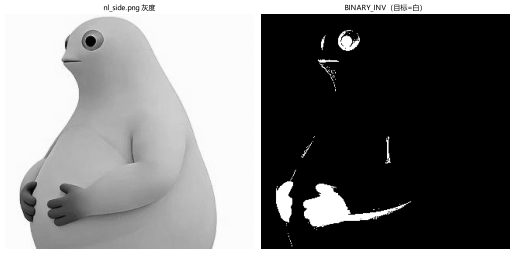

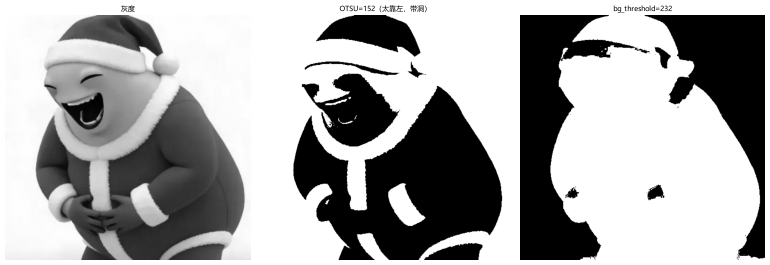

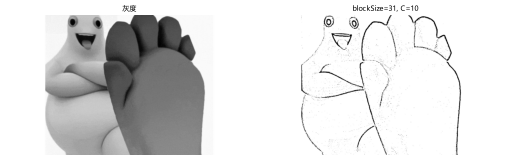

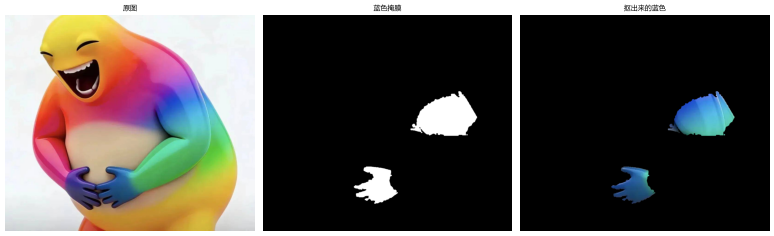

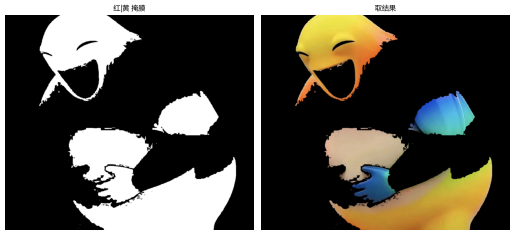

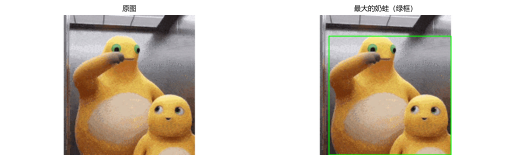

In [7]:
print('=== 5.1 五种 threshold（阈值 127）===')
side = cv2.imread('res/nl_side.png', cv2.IMREAD_GRAYSCALE)
for name, t in [('BINARY', cv2.THRESH_BINARY), ('BINARY_INV', cv2.THRESH_BINARY_INV),
                ('TRUNC', cv2.THRESH_TRUNC), ('TOZERO', cv2.THRESH_TOZERO),
                ('TOZERO_INV', cv2.THRESH_TOZERO_INV)]:
    _, r = cv2.threshold(side, 127, 255, t)
    print(f'  {name:12s} 非零占比={100*np.count_nonzero(r)/r.size:5.1f}%  '
          f'取值={int(r.min())}~{int(r.max())}  唯一值个数={len(np.unique(r))}')
print('  ↑ 只有 BINARY / BINARY_INV 是真正的 0/255 二值图')
print('  ↑ 白底图抠奶蛙 -> 用 BINARY_INV（目标变白）')
show_img(side, cv2.threshold(side, 127, 255, cv2.THRESH_BINARY_INV)[1],
         titles=['nl_side.png 灰度', 'BINARY_INV（目标=白）'])

print()
print('=== 5.3 OTSU 与 bg_threshold 比大小 ===')
def bg_threshold(gray, drop=20):
    border = np.concatenate([gray[0], gray[-1], gray[:, 0], gray[:, -1]])
    return max(int(np.median(border)) - drop, 1)

san = cv2.imread('res/nl_santa.png', cv2.IMREAD_GRAYSCALE)
t_otsu, b_otsu = cv2.threshold(san, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
t_bg = bg_threshold(san)
_, b_bg = cv2.threshold(san, t_bg, 255, cv2.THRESH_BINARY_INV)
print(f'  OTSU={int(t_otsu)}   bg_threshold={t_bg}   灰度中位数={int(np.median(san))}')
print('  ↑ 白底抠图要用 bg_threshold：阈值得落在目标和背景之间的空档')
show_img(san, b_otsu, b_bg, titles=['灰度', f'OTSU={int(t_otsu)}（太靠左，带洞）', f'bg_threshold={t_bg}'])

print()
print('=== 5.4 nl_hd17 的自适应阈值 ===')
h17 = cv2.imread('res/nl_hd17.jpg', cv2.IMREAD_GRAYSCALE)
for bs in [11, 31, 61]:
    for C in [5, 10]:
        ad = cv2.adaptiveThreshold(h17, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, bs, C)
        print(f'  blockSize={bs:3d} C={C:2d} -> 前景占比 {100*np.count_nonzero(ad)/ad.size:5.1f}%')
print('  ↑ 只看数字看不出对不对，一定要看掩膜图')
show_img(h17, cv2.adaptiveThreshold(h17, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, 31, 10),
         titles=['灰度', 'blockSize=31, C=10'])

print()
print('=== 5.5 blockSize 取偶数会怎样 ===')
try:
    cv2.adaptiveThreshold(h17, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 30, 5)
    print('  没报错')
except cv2.error as e:
    print('  报错：', str(e).strip().splitlines()[-1])

print()
print('=== 5.2 纯蓝色区域分割（nl_rainbow）===')
rb = cv2.imread('res/nl_rainbow.png')
rh = cv2.cvtColor(rb, cv2.COLOR_BGR2HSV_FULL)
m = cv2.inRange(rh, np.array([116, 60, 40]), np.array([160, 255, 255]))
m2 = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
print(f'  去噪前 {int(np.count_nonzero(m))} -> 去噪后 {int(np.count_nonzero(m2))}')
blue_only = cv2.bitwise_and(rb, rb, mask=m2)
show_img(rb, m2, blue_only, titles=['原图', '蓝色掩膜', '抠出来的蓝色'])

print()
print('=== 5.3 同时分割红 + 黄 ===')
ry = cv2.inRange(rh, np.array([15, 60, 40]), np.array([48, 255, 255]))
both = cv2.bitwise_or(m2, ry)
print(f'  红+黄 共 {int(np.count_nonzero(both))} 像素')
show_img(both, cv2.bitwise_and(rb, rb, mask=both), titles=['红|黄 掩膜', '取结果'])

print()
print('=== 5.4（定位）nl_hd13 里最大的奶蛙 ===')
img = cv2.imread('res/nl_hd13.jpg')
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)
mask = cv2.inRange(hsv, np.array([15, 60, 120]), np.array([40, 255, 255]))
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(f'  轮廓数 = {len(contours)}')
if contours:                                   # ⚠️ 全黑掩膜时 contours 是空列表
    big = max(contours, key=cv2.contourArea)
    bx, by, bw, bh = cv2.boundingRect(big)
    print(f'  最大 bbox = ({bx}, {by}, {bw}, {bh})')
    vis = img.copy()
    cv2.rectangle(vis, (bx, by), (bx + bw, by + bh), (0, 255, 0), 5)
    show_img(img, vis, titles=['原图', '最大的奶蛙（绿框）'])
else:
    print('  掩膜是空的 —— 换图后 HSV 区间要微调')

---
# 第 6 章 图像形态学变换

**练习 1**：`MORPH_RECT` 是**正方形**核，斜笔画会被"方方正正地"啃掉、拐角出现直角；
  `MORPH_ELLIPSE` 是**圆形**核，对各个方向一视同仁，斜笔画变细更均匀。
  **文字/圆形目标用椭圆核，矩形目标用矩形核。**

**练习 2**：`OPEN` 去「多出来的小白点」（前景占比略降），
  `CLOSE` 补「目标内部的小黑洞」（略升）；先开后闭 = 先除噪点再补洞，最干净。

**练习 3**：`MORPH_GRADIENT` 是「**区域的边界**」（二值图输入，带状、一定闭合）；
  `Canny` 是「**灰度的突变**」（灰度图输入，单像素细线、可能断开）。

**练习 4**：星空图效果**不理想** —— OTSU 会把成片的云气一起选成前景，
  开运算只能抹掉比核小的孤立点。更好的方向是**提高固定阈值**或**顶帽变换（`MORPH_TOPHAT`）**。

**练习 5（思考）**：**填不上，需要至少 21×21 的核。**
  闭运算能填的洞，尺寸必须"放不下核"；核能整个塞进洞里时，中心点没有洞外邻域可参考。
  ⚠️ 核也不能无限加大，否则目标本身的凹处会被一起填平。

=== 6.1 三种结构元素长什么样 ===
MORPH_RECT(5,5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

MORPH_ELLIPSE(5,5):
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]

MORPH_CROSS(5,5):
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]

=== 6.2/6.3 腐蚀膨胀、开闭运算、形态学梯度 ===
  前景占比：原图 3.4%  OPEN 3.2%  CLOSE 3.5%  OPEN后CLOSE 3.3%
  MORPH_GRADIENT 前景 1.2%   Canny 前景 0.7%
  ↑ GRADIENT 是"区域的边界"（粗、闭合）；Canny 是"灰度的突变"（细线、可能断）

=== 6.4 nl_galaxy（星空）的掩膜清理 ===
  OTSU 自动阈值 = 139（灰度均值 135.8）
  开运算后"前景"占比 = 43.89%  <- 成片云气抹不掉

=== 6.5（思考）20×20 的洞，5×5 的核能补上吗？ ===
  核  5x 5 -> 洞里还剩 92 个黑像素
  核 11x11 -> 洞里还剩 0 个黑像素
  核 21x21 -> 洞里还剩 0 个黑像素
  ↑ 核必须"放不进洞里"才能填上：洞 10x10 时核要 >= 11
  （20x20 的洞同理，核要 >= 21）


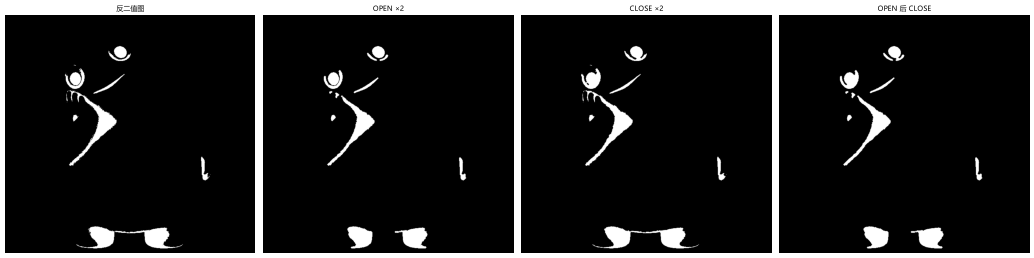

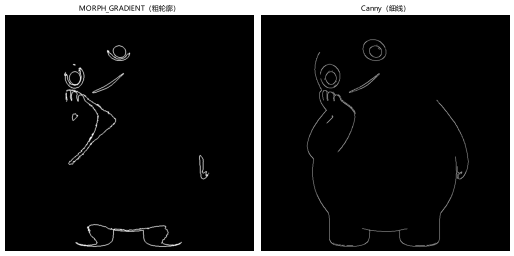

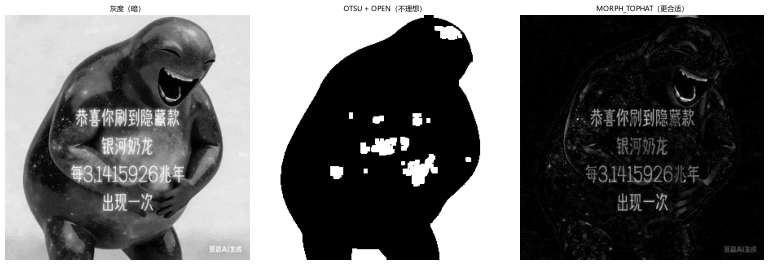

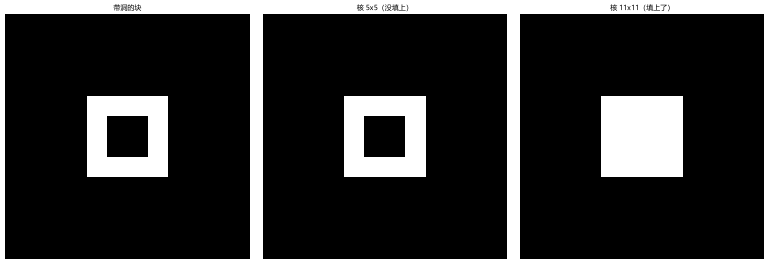

In [8]:
print('=== 6.1 三种结构元素长什么样 ===')
for name, shape in [('MORPH_RECT(5,5)', cv2.MORPH_RECT), ('MORPH_ELLIPSE(5,5)', cv2.MORPH_ELLIPSE),
                    ('MORPH_CROSS(5,5)', cv2.MORPH_CROSS)]:
    print(f'{name}:')
    print(cv2.getStructuringElement(shape, (5, 5)))
    print()

print('=== 6.2/6.3 腐蚀膨胀、开闭运算、形态学梯度 ===')
th = cv2.imread('res/nl_think.png', cv2.IMREAD_GRAYSCALE)
_, bi = cv2.threshold(th, 160, 255, cv2.THRESH_BINARY_INV)
k = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
o = cv2.morphologyEx(bi, cv2.MORPH_OPEN, k, iterations=2)
cl = cv2.morphologyEx(bi, cv2.MORPH_CLOSE, k, iterations=2)
oc = cv2.morphologyEx(o, cv2.MORPH_CLOSE, k, iterations=2)
print(f'  前景占比：原图 {100*np.count_nonzero(bi)/bi.size:.1f}%  '
      f'OPEN {100*np.count_nonzero(o)/o.size:.1f}%  '
      f'CLOSE {100*np.count_nonzero(cl)/cl.size:.1f}%  '
      f'OPEN后CLOSE {100*np.count_nonzero(oc)/oc.size:.1f}%')
show_img(bi, o, cl, oc, titles=['反二值图', 'OPEN ×2', 'CLOSE ×2', 'OPEN 后 CLOSE'])

grad = cv2.morphologyEx(bi, cv2.MORPH_GRADIENT, k, iterations=1)
canny = cv2.Canny(th, 100, 200)
print(f'  MORPH_GRADIENT 前景 {100*np.count_nonzero(grad)/grad.size:.1f}%   '
      f'Canny 前景 {100*np.count_nonzero(canny)/canny.size:.1f}%')
print('  ↑ GRADIENT 是"区域的边界"（粗、闭合）；Canny 是"灰度的突变"（细线、可能断）')
show_img(grad, canny, titles=['MORPH_GRADIENT（粗轮廓）', 'Canny（细线）'])

print()
print('=== 6.4 nl_galaxy（星空）的掩膜清理 ===')
gal = cv2.imread('res/nl_galaxy.png', cv2.IMREAD_GRAYSCALE)
t_ot, b_ot = cv2.threshold(gal, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
b_op = cv2.morphologyEx(b_ot, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
print(f'  OTSU 自动阈值 = {int(t_ot)}（灰度均值 {gal.mean():.1f}）')
print(f'  开运算后"前景"占比 = {100*np.count_nonzero(b_op)/b_op.size:.2f}%  <- 成片云气抹不掉')
# 顶帽变换：专门提取"比周围亮的细小结构"
tophat = cv2.morphologyEx(gal, cv2.MORPH_TOPHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
show_img(gal, b_op, tophat, titles=['灰度（暗）', 'OTSU + OPEN（不理想）', 'MORPH_TOPHAT（更合适）'])

print()
print('=== 6.5（思考）20×20 的洞，5×5 的核能补上吗？ ===')
big = np.zeros((60, 60), np.uint8)
big[20:40, 20:40] = 255                      # 20x20 的白块
hollow = big.copy()
hollow[25:35, 25:35] = 0                     # 中间挖个 10x10 的洞当演示
for ks in [5, 11, 21]:
    kk = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ks, ks))
    filled = cv2.morphologyEx(hollow, cv2.MORPH_CLOSE, kk)
    print(f'  核 {ks:2d}x{ks:2d} -> 洞里还剩 {int(np.count_nonzero(filled[25:35,25:35]==0))} 个黑像素')
print('  ↑ 核必须"放不进洞里"才能填上：洞 10x10 时核要 >= 11')
print('  （20x20 的洞同理，核要 >= 21）')
show_img(hollow, cv2.morphologyEx(hollow, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8)),
         cv2.morphologyEx(hollow, cv2.MORPH_CLOSE, np.ones((11, 11), np.uint8)),
         titles=['带洞的块', '核 5x5（没填上）', '核 11x11（填上了）'])

---
# 第 7 章 图像卷积

**练习 1**：`BORDER_CONSTANT` 默认补 **0（黑）**，大核会把边缘整体拉黑
  （上边缘均值 110.9 vs 全图 170.2）→ 看起来就是一圈**暗色带**。
  `REPLICATE` / `REFLECT` 不引入假的 0，边缘就正常。**这就是默认用 `REFLECT_101` 的原因。**

**练习 2**：把核的正负号摆到**对角**上 → 只对"垂直于该对角"的边缘敏感。
  `[[1,0,-1],[0,0,0],[-1,0,1]]` 找 ↘ 方向的变化；转置一下找 ↗ 方向。

**练习 3**：核和为 0 时必须用 `CV_32F`。
  `ddepth=-1`（uint8）**存不下负数 → 负响应被截断成 0**（实测 −319 → 0），
  一半的边缘信息直接丢；而且正值还容易饱和到 255。

**练习 4（思考）**：`BORDER_REFLECT` 会在边界**重复一个像素**，对导数类算子相当于
  人为制造零梯度；`REFLECT_101` 的镜像轴落在像素之间，不重复，边界梯度更接近真实。

**自测**：只放大 2 倍用 `cv2.resize`（专门为缩放设计，能选插值）；
  `warpAffine` 是通用仿射变换，除非同时还要旋转/平移。

=== 7.1 31×31 均值滤波的边界差异 ===
  CONSTANT     上边缘30行均值= 110.9   全图均值= 170.2
  REPLICATE    上边缘30行均值= 247.3   全图均值= 209.7
  REFLECT      上边缘30行均值= 243.7   全图均值= 209.3
  REFLECT_101  上边缘30行均值= 243.3   全图均值= 209.3
  原图全图均值 = 204.6
  ↑ CONSTANT 补 0 -> 边缘被拉黑 60 个灰阶，这就是"大核 + 错误边界"的色带

=== 7.2 只保留对角线方向的边缘 ===
  对角核 = [[1.0, 0.0, -1.0], [0.0, 0.0, 0.0], [-1.0, 0.0, 1.0]]

=== 7.3 ddepth = -1 vs CV_32F ===
  filter2D CV_32F   min/max = -319 / 299
  filter2D ddepth=-1 min/max = 0 / 255   <- 负值被截断成 0
  Sobel    CV_32F   min/max = -991 / 723
  Sobel    ddepth=-1 min/max = 0 / 255
  ↑ 核和为 0 的算子（边缘核/拉普拉斯）一律用 CV_32F


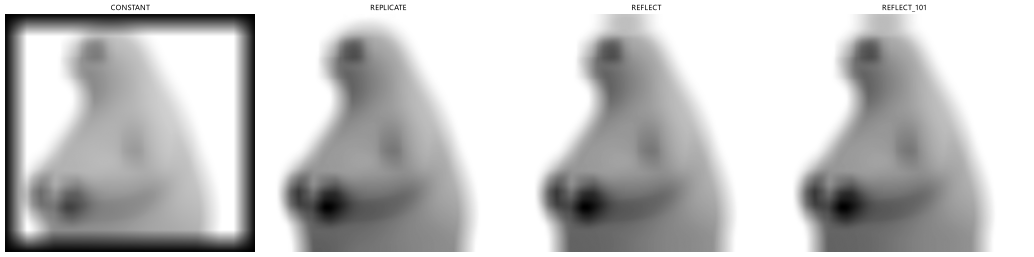

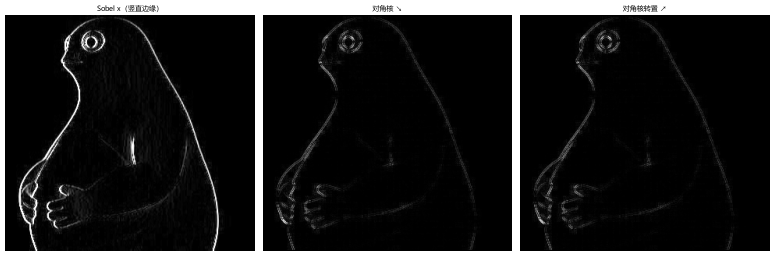

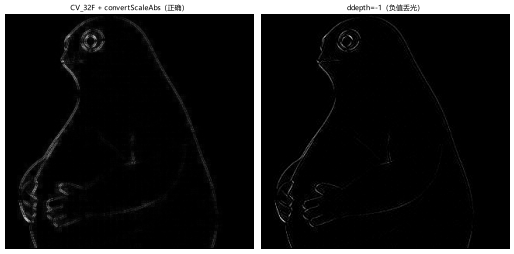

In [9]:
print('=== 7.1 31×31 均值滤波的边界差异 ===')
sd = cv2.imread('res/nl_side.png', cv2.IMREAD_GRAYSCALE)
res = []
for bt, nm in [(cv2.BORDER_CONSTANT, 'CONSTANT'), (cv2.BORDER_REPLICATE, 'REPLICATE'),
               (cv2.BORDER_REFLECT, 'REFLECT'), (cv2.BORDER_REFLECT_101, 'REFLECT_101')]:
    pad = cv2.copyMakeBorder(sd, 15, 15, 15, 15, bt)
    r = cv2.blur(pad, (31, 31))
    res.append(r)
    print(f'  {nm:12s} 上边缘30行均值={r[0:30,:].mean():6.1f}   全图均值={r.mean():6.1f}')
print(f'  原图全图均值 = {sd.mean():.1f}')
print('  ↑ CONSTANT 补 0 -> 边缘被拉黑 60 个灰阶，这就是"大核 + 错误边界"的色带')
show_img(*res, titles=['CONSTANT', 'REPLICATE', 'REFLECT', 'REFLECT_101'])

print()
print('=== 7.2 只保留对角线方向的边缘 ===')
kd = np.array([[1, 0, -1], [0, 0, 0], [-1, 0, 1]], np.float32)     # ↘
t_d = cv2.convertScaleAbs(cv2.filter2D(sd, cv2.CV_32F, kd))
t_u = cv2.convertScaleAbs(cv2.filter2D(sd, cv2.CV_32F, kd.T))      # ↗（转置）
h_edge = cv2.convertScaleAbs(cv2.Sobel(sd, cv2.CV_32F, 1, 0, ksize=3))
print('  对角核 =', kd.tolist())
show_img(h_edge, t_d, t_u, titles=['Sobel x（竖直边缘）', '对角核 ↘', '对角核转置 ↗'])

print()
print('=== 7.3 ddepth = -1 vs CV_32F ===')
f32 = cv2.filter2D(sd, cv2.CV_32F, kd)
u8 = cv2.filter2D(sd, -1, kd)
print(f'  filter2D CV_32F   min/max = {f32.min():.0f} / {f32.max():.0f}')
print(f'  filter2D ddepth=-1 min/max = {u8.min()} / {u8.max()}   <- 负值被截断成 0')
s32 = cv2.Sobel(sd, cv2.CV_32F, 1, 0)
s8 = cv2.Sobel(sd, -1, 1, 0)
print(f'  Sobel    CV_32F   min/max = {s32.min():.0f} / {s32.max():.0f}')
print(f'  Sobel    ddepth=-1 min/max = {s8.min()} / {s8.max()}')
print('  ↑ 核和为 0 的算子（边缘核/拉普拉斯）一律用 CV_32F')
show_img(cv2.convertScaleAbs(f32), u8, titles=['CV_32F + convertScaleAbs（正确）', 'ddepth=-1（负值丢光）'])

---
# 第 8 章 图像滤波与去噪

**练习 1**：3% 椒盐噪声下，与干净原图的平均绝对差：均值 4.15 / 高斯 4.02 / **中值 1.04**。
  **中值完胜** —— 噪声是"少数像素被推到极值"，中值取排序中间值，极端点影响不到它。

**练习 2**：**`sigma` 决定"模糊多少"，`ksize` 只决定"用多大窗口去近似这个高斯"。**
  实测 sigma=2 时 ksize 从 11 起结果不再变化（MAD 都是 1.46）；
  而 ksize=21 固定、sigma 从 1 到 10，MAD 单调上升 0.72 → 2.82。
  经验：**先定 sigma，再把 ksize 取成 6σ 左右的奇数**。

**练习 3**：`sigmaColor` 是"颜色差多少以内算同一个物体"的门槛。
  小（30）→ 边缘保留最死；大（100+）→ 退化成普通高斯，"水彩画"消失。
  代价：慢、参数敏感、非线性（不能拆成两次一维）。

**练习 4**：别只看一个总平均差，**分成"噪声点处"和"原本干净处"两组**
  —— 前者是去噪的功劳，后者才是滤波的代价。

**自测**：第一步永远是**判断噪声类型**（椒盐→中值；高斯→高斯/双边），
  第二步看约束（保边→双边），第三步**放大看边缘**验证。

=== 8.1 3% 椒盐噪声 + 三种滤波 ===
  均值 cv2.blur          与干净原图的平均绝对差 =  4.15
  高斯 GaussianBlur      与干净原图的平均绝对差 =  4.02
  中值 medianBlur        与干净原图的平均绝对差 =  1.04
  ↑ 中值最小 —— 它专治椒盐噪声

=== 8.2 sigma 与 ksize 各控制什么 ===
  [A] sigma=2 固定，改 ksize：
      ksize= 3 -> MAD vs 原图 = 0.60
      ksize= 5 -> MAD vs 原图 = 1.06
      ksize=11 -> MAD vs 原图 = 1.46
      ksize=21 -> MAD vs 原图 = 1.46
      ksize=31 -> MAD vs 原图 = 1.46
      ↑ ksize >= 11 之后不再变化 —— 窗口够大就够了
  [B] ksize=21 固定，改 sigma：
      sigma= 0 -> MAD vs 原图 = 2.07
      sigma= 1 -> MAD vs 原图 = 0.72
      sigma= 2 -> MAD vs 原图 = 1.46
      sigma= 5 -> MAD vs 原图 = 2.43
      sigma=10 -> MAD vs 原图 = 2.82
      ↑ sigma 越大越糊 —— 它才是"模糊程度"的旋钮

=== 8.3 双边滤波的 sigmaColor ===
  sigmaColor= 30  与高斯结果的平均绝对差 = 0.60
  sigmaColor=100  与高斯结果的平均绝对差 = 0.32
  sigmaColor=250  与高斯结果的平均绝对差 = 0.33
  ↑ 越小越保边；越大越像普通高斯（"水彩画"消失）

=== 8.4 分组看残差：去噪的功劳 vs 滤波的代价 ===
  噪声点处平均残差 =   1.18  <- 去噪的功劳
  原本干净处平均残差 =   1.04  <- 滤波的代价（细节被磨）


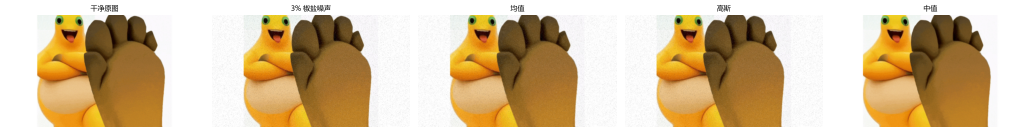

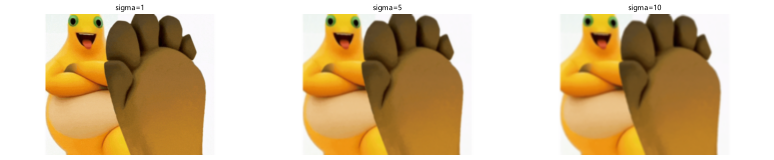

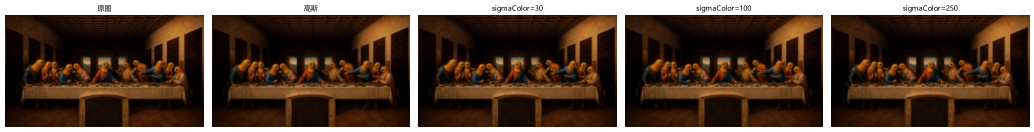

In [10]:
print('=== 8.1 3% 椒盐噪声 + 三种滤波 ===')
img = cv2.imread('res/nl_hd17.jpg')
rng = np.random.default_rng(42)
noisy = img.copy()
r = rng.random(img.shape[:2])
noisy[r < 0.015] = 0
noisy[(r >= 0.015) & (r < 0.03)] = 255
filters = [('均值 cv2.blur', lambda i: cv2.blur(i, (5, 5))),
           ('高斯 GaussianBlur', lambda i: cv2.GaussianBlur(i, (5, 5), 0)),
           ('中值 medianBlur', lambda i: cv2.medianBlur(i, 5))]
outs = []
for nm, fn in filters:
    o = fn(noisy)
    outs.append(o)
    print(f'  {nm:20s} 与干净原图的平均绝对差 = {abs(o.astype(int)-img.astype(int)).mean():5.2f}')
print('  ↑ 中值最小 —— 它专治椒盐噪声')
show_img(img, noisy, *outs, titles=['干净原图', '3% 椒盐噪声', '均值', '高斯', '中值'])

print()
print('=== 8.2 sigma 与 ksize 各控制什么 ===')
print('  [A] sigma=2 固定，改 ksize：')
for ks in [3, 5, 11, 21, 31]:
    print(f'      ksize={ks:2d} -> MAD vs 原图 = '
          f'{abs(cv2.GaussianBlur(img,(ks,ks),2).astype(int)-img.astype(int)).mean():.2f}')
print('      ↑ ksize >= 11 之后不再变化 —— 窗口够大就够了')
print('  [B] ksize=21 固定，改 sigma：')
for sg in [0, 1, 2, 5, 10]:
    print(f'      sigma={sg:2d} -> MAD vs 原图 = '
          f'{abs(cv2.GaussianBlur(img,(21,21),sg).astype(int)-img.astype(int)).mean():.2f}')
print('      ↑ sigma 越大越糊 —— 它才是"模糊程度"的旋钮')
show_img(cv2.GaussianBlur(img, (21, 21), 1), cv2.GaussianBlur(img, (21, 21), 5),
         cv2.GaussianBlur(img, (21, 21), 10), titles=['sigma=1', 'sigma=5', 'sigma=10'])

print()
print('=== 8.3 双边滤波的 sigmaColor ===')
cl = cv2.imread('res/nl_classic1.jpg')
gauss = cv2.GaussianBlur(cl, (9, 9), 0)
outs = []
for sc in [30, 100, 250]:
    bf = cv2.bilateralFilter(cl, 9, sc, sc)
    outs.append(bf)
    print(f'  sigmaColor={sc:3d}  与高斯结果的平均绝对差 = '
          f'{abs(bf.astype(int)-gauss.astype(int)).mean():.2f}')
print('  ↑ 越小越保边；越大越像普通高斯（"水彩画"消失）')
show_img(cl, gauss, *outs, titles=['原图', '高斯', 'sigmaColor=30', 'sigmaColor=100', 'sigmaColor=250'])

print()
print('=== 8.4 分组看残差：去噪的功劳 vs 滤波的代价 ===')
med = cv2.medianBlur(noisy, 5)
diff = cv2.absdiff(med, img)
noise_mask = (r < 0.03)
print(f'  噪声点处平均残差 = {diff[noise_mask].mean():6.2f}  <- 去噪的功劳')
print(f'  原本干净处平均残差 = {diff[~noise_mask].mean():6.2f}  <- 滤波的代价（细节被磨）')

---
# 第 9 章 几何变换

**练习 1**：`(1080,1920,3) -> (360,640,3)`，缩放比 1/3。
  **缩小用 `INTER_AREA`，放大用 `INTER_CUBIC` / `INTER_LINEAR`。**

**练习 2**：三次平移的输出 shape 都是 `(300,300,3)` ——
  **输出尺寸由 `dsize` 决定，不会自动变大**，移出画布的内容不会补回来。

**练习 3**：角度**正数 = 逆时针**；旋转 30°/60° 时四个角会被切掉；
  90° 其实用 `cv2.rotate` 更快更准（不插值）。

**练习 4**：只动"下面那个点"的 x → 得到错切实测 `M = [[1,-0.2,0],[0,1,0]]`，
  y=0 那行不变、y 越大偏移越多。

**练习 5（思考）**：透视变换有 8 个自由度，每个点对给 2 个方程 → 必须 4 个点。
  3 个点是仿射变换（6 自由度），**表达不了"近大远小"**。

**练习 6**：交换第 1、2 个点 → 结果整体镜像。
  **矩阵照算不误**，它不检查你给的点合不合理。所以取完点**一定要画回原图确认**。

**练习 7**：50 次旋转耗时 —— NEAREST 2.1ms / LINEAR 2.8ms / CUBIC 12.4ms / **LANCZOS4 242ms**。
  实时用 `LINEAR`；`NEAREST` 只在"必须保持原始像素值"（掩膜/标签图）时用。

**练习 8**：`> 3` 而不是 `> 0`（躲开压缩噪点），再取 `boundingRect` 切片。

**练习 9**：坐标自己量，**画回原图确认**这一步千万别省。

**练习 10**：`process_MHZ()` 实测得到 **4 个顶点、`isContourConvex=True`** ✅。
  ⚠️ `approxPolyDP` 的顶点顺序不保证，喂给透视变换前要排序，
  而且 `eps` 取小了会变成 7 个顶点、非凸。

**练习 11（思考）**：会有残留变形 —— 镜头畸变（非线性，要先 `undistort`）
  和纸张不平（不是平面，任何平面投影都修不好）。正确顺序：**先去畸变 → 再透视矫正**。

=== 9.1 缩到宽 640 ===
  (1080, 1920, 3) -> (360, 640, 3)   缩放比=0.333333

=== 9.2 / 9.3 平移与旋转（用 res/nl_side.png 当素材）===
  素材 shape = (302, 320, 3)
  平移( 100,   0) -> 输出 shape (302, 320, 3)  <- dsize 决定的，不会变大
  平移(   0, 100) -> 输出 shape (302, 320, 3)  <- dsize 决定的，不会变大
  平移( -50, -50) -> 输出 shape (302, 320, 3)  <- dsize 决定的，不会变大
  旋转 30°（正数=逆时针）-> 输出 shape (302, 320, 3)
  旋转 60°（正数=逆时针）-> 输出 shape (302, 320, 3)
  旋转 90°（正数=逆时针）-> 输出 shape (302, 320, 3)

=== 9.4 仿射：上边拉长、下边不变 ===
  M = [[1.0, -0.199, 0.0], [0.0, 1.0, 0.0]]

=== 9.7 插值方式的速度对比（50 次旋转）===
  NEAREST       2.6 ms / 50 次
  LINEAR        8.8 ms / 50 次
  CUBIC        32.7 ms / 50 次
  LANCZOS4    374.7 ms / 50 次
  ↑ 实时用 LINEAR；NEAREST 只在必须保持原始像素值时用

=== 9.8 自动裁掉黑边 ===
  非黑区 boundingRect = (9, 10, 311, 292)
  裁剪后 (292, 311, 3)


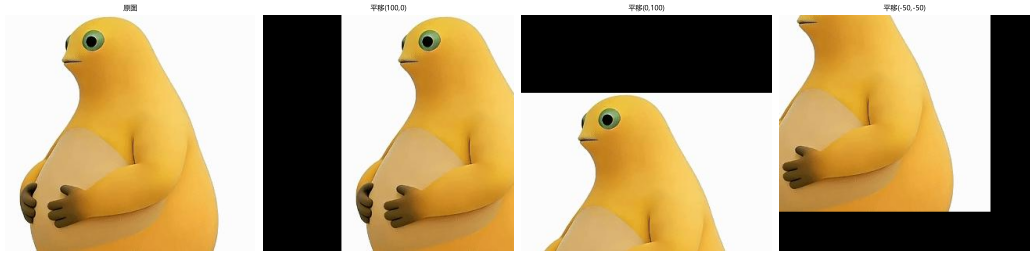

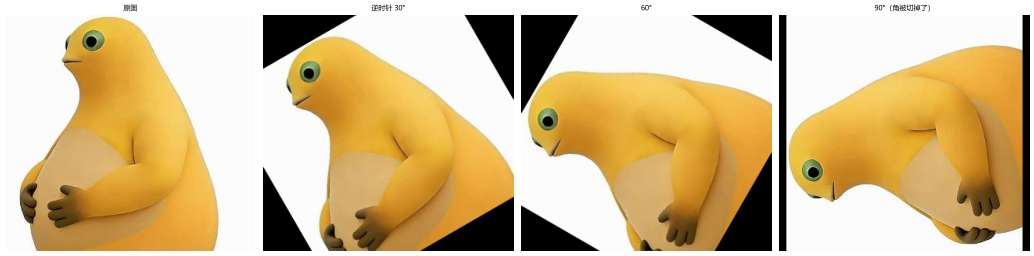

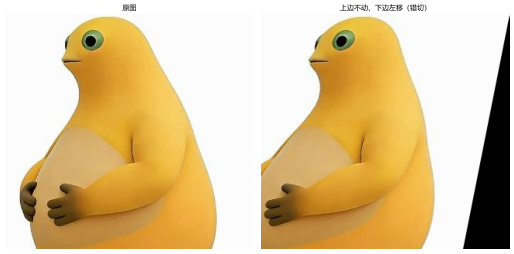

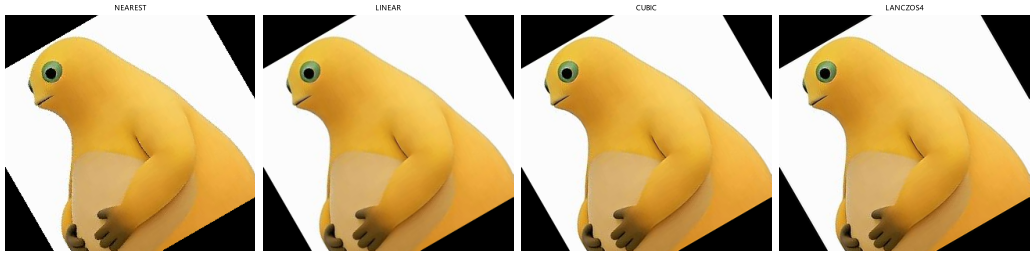

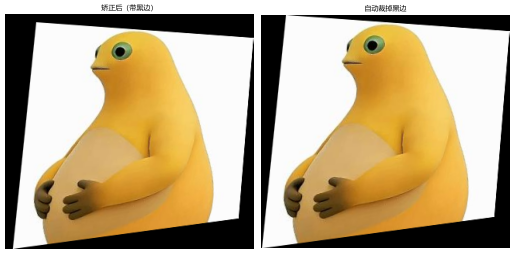

In [11]:
print('=== 9.1 缩到宽 640 ===')
hd = cv2.imread('res/nl_hd01.jpg')
sc = 640 / hd.shape[1]
small = cv2.resize(hd, (640, int(hd.shape[0] * sc)), interpolation=cv2.INTER_AREA)
print(f'  {hd.shape} -> {small.shape}   缩放比={sc:.6f}')

print()
print('=== 9.2 / 9.3 平移与旋转（用 res/nl_side.png 当素材）===')
card = cv2.imread('res/nl_side.png')
print('  素材 shape =', card.shape)
moves = []
for dx, dy in [(100, 0), (0, 100), (-50, -50)]:
    M = np.float32([[1, 0, dx], [0, 1, dy]])
    mv = cv2.warpAffine(card, M, (card.shape[1], card.shape[0]))
    moves.append(mv)
    print(f'  平移({dx:4d},{dy:4d}) -> 输出 shape {mv.shape}  <- dsize 决定的，不会变大')
show_img(card, *moves, titles=['原图', '平移(100,0)', '平移(0,100)', '平移(-50,-50)'])

rots = []
for ang in [30, 60, 90]:
    M = cv2.getRotationMatrix2D((card.shape[1] / 2, card.shape[0] / 2), ang, 1)
    rots.append(cv2.warpAffine(card, M, (card.shape[1], card.shape[0])))
    print(f'  旋转 {ang:2d}°（正数=逆时针）-> 输出 shape {rots[-1].shape}')
show_img(card, *rots, titles=['原图', '逆时针 30°', '60°', '90°（角被切掉了）'])

print()
print('=== 9.4 仿射：上边拉长、下边不变 ===')
h, w = card.shape[:2]
pts1 = np.float32([[0, 0], [w, 0], [0, h]])
pts2 = np.float32([[0, 0], [w, 0], [-60, h]])       # 只把左下角往左拉
M = cv2.getAffineTransform(pts1, pts2)
print('  M =', np.round(M, 3).tolist())
sheared = cv2.warpAffine(card, M, (w, h))
show_img(card, sheared, titles=['原图', '上边不动、下边左移（错切）'])

print()
print('=== 9.7 插值方式的速度对比（50 次旋转）===')
import time
M = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1)
for itp, nm in [(cv2.INTER_NEAREST, 'NEAREST'), (cv2.INTER_LINEAR, 'LINEAR'),
                (cv2.INTER_CUBIC, 'CUBIC'), (cv2.INTER_LANCZOS4, 'LANCZOS4')]:
    t0 = time.perf_counter()
    for _ in range(50):
        cv2.warpAffine(card, M, (w, h), flags=itp)
    print(f'  {nm:9s} {(time.perf_counter()-t0)*1000:7.1f} ms / 50 次')
print('  ↑ 实时用 LINEAR；NEAREST 只在必须保持原始像素值时用')
show_img(*[cv2.warpAffine(card, M, (w, h), flags=i) for i in
           (cv2.INTER_NEAREST, cv2.INTER_LINEAR, cv2.INTER_CUBIC, cv2.INTER_LANCZOS4)],
         titles=['NEAREST', 'LINEAR', 'CUBIC', 'LANCZOS4'])

print()
print('=== 9.8 自动裁掉黑边 ===')
src = card
dst_pts = np.float32([[40, 10], [w - 1, 30], [w - 20, h - 40], [10, h - 1]])
src_pts = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
Mw = cv2.getPerspectiveTransform(src_pts, dst_pts)
warped = cv2.warpPerspective(src, Mw, (w, h))
g = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)
ys, xs = np.where(g > 3)                     # 用 >3，躲开插值产生的 1~2 噪点
x0, y0, x1, y1 = xs.min(), ys.min(), xs.max(), ys.max()
print(f'  非黑区 boundingRect = ({x0}, {y0}, {x1-x0+1}, {y1-y0+1})')
print(f'  裁剪后 {warped[y0:y1+1, x0:x1+1].shape}')
show_img(warped, warped[y0:y1+1, x0:x1+1], titles=['矫正后（带黑边）', '自动裁掉黑边'])

=== 9.10（重点）process_MHZ：自动取梅花桩四个角点 ===
  MHZ.png (667, 630, 3)  红色掩膜占比 21.0%
  顶点数 = 4   isContourConvex = True   <- 两条验收标准都满足
  四个角点 = [[458, 112], [92, 133], [133, 483], [459, 430]]

  eps 取太小会退化（实测）：
    eps=0.01*周长 -> 顶点=7  凸=False
    eps=0.02*周长 -> 顶点=4  凸=True
    eps=0.03*周长 -> 顶点=4  凸=True
  全自动矫正输出 (352, 366, 3)


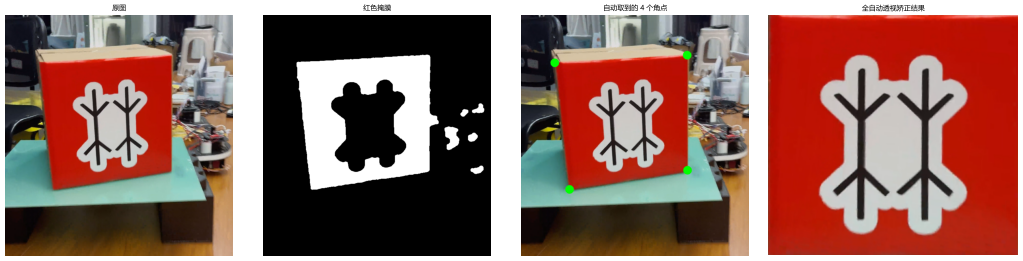

In [12]:
print('=== 9.10（重点）process_MHZ：自动取梅花桩四个角点 ===')
def process_MHZ(img):
    """返回梅花桩（红箱子）的四个角点。选学第 4 章 4.4 的验收标准：
    isContourConvex == True 且 approxPolyDP 顶点数 == 4。"""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)
    # ① 红色跨 0 点，必须两段合并
    red = (cv2.inRange(hsv, np.array([243, 80, 80]), np.array([255, 255, 255])) |
           cv2.inRange(hsv, np.array([0, 80, 80]), np.array([14, 255, 255])))
    # ② 闭运算补洞 -> 开运算去噪
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    red = cv2.morphologyEx(red, cv2.MORPH_CLOSE, k, iterations=2)
    red = cv2.morphologyEx(red, cv2.MORPH_OPEN, k, iterations=1)
    # ③ 最大轮廓 -> 多边形逼近
    contours, _ = cv2.findContours(red, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    biggest = max(contours, key=cv2.contourArea)
    return cv2.approxPolyDP(biggest, 0.02 * cv2.arcLength(biggest, True), True), red, biggest


mhz = cv2.imread('res/MHZ.png')
ap, red_mask, biggest = process_MHZ(mhz)
print(f'  MHZ.png {mhz.shape}  红色掩膜占比 {100*np.count_nonzero(red_mask)/red_mask.size:.1f}%')
print(f'  顶点数 = {len(ap)}   isContourConvex = {cv2.isContourConvex(ap)}   <- 两条验收标准都满足')
print('  四个角点 =', ap.reshape(-1, 2).tolist())

print()
print('  eps 取太小会退化（实测）：')
for rr in [0.01, 0.02, 0.03]:
    a = cv2.approxPolyDP(biggest, rr * cv2.arcLength(biggest, True), True)
    print(f'    eps={rr}*周长 -> 顶点={len(a)}  凸={cv2.isContourConvex(a)}')

# 按 左上->右上->右下->左下 排序后做全自动透视矫正
src = ap.reshape(4, 2).astype(np.float32)
s = src.sum(axis=1)
d = np.diff(src, axis=1).ravel()
ordered = np.array([src[np.argmin(s)], src[np.argmin(d)],
                    src[np.argmax(s)], src[np.argmax(d)]], np.float32)
ow = int(max(np.linalg.norm(ordered[0]-ordered[1]), np.linalg.norm(ordered[3]-ordered[2])))
oh = int(max(np.linalg.norm(ordered[0]-ordered[3]), np.linalg.norm(ordered[1]-ordered[2])))
Mp = cv2.getPerspectiveTransform(ordered, np.float32([[0, 0], [ow, 0], [ow, oh], [0, oh]]))
flat = cv2.warpPerspective(mhz, Mp, (ow, oh))
print(f'  全自动矫正输出 {flat.shape}')

vis = mhz.copy()
for p in ap.reshape(-1, 2):
    cv2.circle(vis, tuple(int(v) for v in p), 12, (0, 255, 0), -1)
show_img(mhz, red_mask, vis, flat, titles=['原图', '红色掩膜', '自动取到的 4 个角点', '全自动透视矫正结果'])

---
# 第 10 章 在图像上画图

**练习 1**：`thickness=-1`（或 `cv2.FILLED`）是**实心**；颜色是 **BGR**，
  `(0,0,255)` 才是红。

**练习 2**：`(i + j) % 2 == 0` 就是棋盘格判据；
  `cv2.rectangle` 的两个点是**对角**（左上 + 右下），不是"左上 + 宽高"。

**练习 3**：叠网格是**读坐标最可靠的办法** —— 后面透视变换、算 ROI、报 bug 都靠它。

**练习 4**：`org` 的 y 不能写太小，否则文字上半截被切掉（因为它是**左下角**）。

**练习 5（思考）**：`org` 是文字的**左下角（基线左端）**。
  想"顶部对齐 y0"要写 `(x, y0 + 字高)`，字高用 `cv2.getTextSize` 拿。

**自测**：`(x, y)` 和 `[y, x]` 是**同一套坐标系**，只是写的顺序反过来。

=== 10.1 400x400 画布 + 中心红色实心圆 ===
  画布 (400, 400, 3)  圆心像素 [0, 0, 255]（BGR，所以 (0,0,255) 是红）
  半径 80 应落在 (200,280) -> 实际 [0, 0, 255]
  半径 80 应落在 (200,120) -> 实际 [0, 0, 255]
  半径 80 应落在 (120,200) -> 实际 [0, 0, 255]
  半径 80 应落在 (280,200) -> 实际 [0, 0, 255]

=== 10.2 8x8 棋盘格 ===
  左上 [255, 255, 255]  右边一格 [255, 255, 255]  <- (i+j)%2 就是判据

=== 10.3 给 nl_point.png 加坐标网格（间隔 100）===
  (690, 668, 3) -> 竖线 7 条、横线 7 条

=== 10.4 在 nl_hd01 左上角写 RobotIC ===
  getTextSize -> 宽高 (285, 68)，基线偏移 1
  ↑ org 是文字的"左下角"；想顶部对齐就写 (x, y0 + 字高)


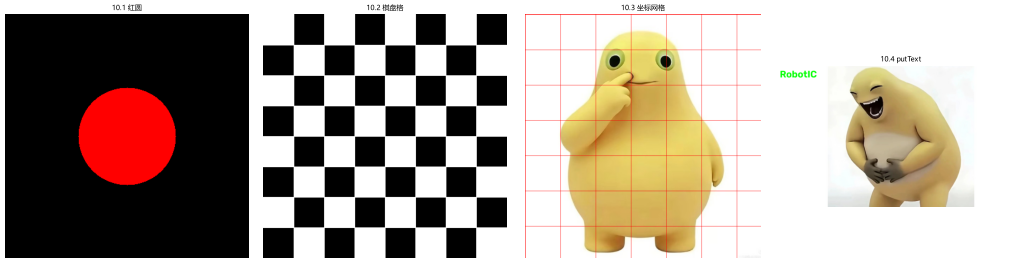

In [13]:
print('=== 10.1 400x400 画布 + 中心红色实心圆 ===')
canvas = np.zeros((400, 400, 3), np.uint8)
cv2.circle(canvas, (200, 200), 80, (0, 0, 255), -1)
print(f'  画布 {canvas.shape}  圆心像素 {canvas[200,200].tolist()}（BGR，所以 (0,0,255) 是红）')
for x, y in [(200, 280), (200, 120), (120, 200), (280, 200)]:
    print(f'  半径 80 应落在 ({x},{y}) -> 实际 {canvas[y,x].tolist()}')

print()
print('=== 10.2 8x8 棋盘格 ===')
bd = np.zeros((400, 400, 3), np.uint8)
cell = 50
for i in range(8):
    for j in range(8):
        if (i + j) % 2 == 0:
            cv2.rectangle(bd, (j * cell, i * cell), ((j + 1) * cell, (i + 1) * cell),
                          (255, 255, 255), -1)
print(f'  左上 {bd[0,0].tolist()}  右边一格 {bd[0,cell].tolist()}  <- (i+j)%2 就是判据')

print()
print('=== 10.3 给 nl_point.png 加坐标网格（间隔 100）===')
gp = cv2.imread('res/nl_point.png')
for x in range(0, gp.shape[1], 100):
    cv2.line(gp, (x, 0), (x, gp.shape[0]), (0, 0, 255), 1)
for y in range(0, gp.shape[0], 100):
    cv2.line(gp, (0, y), (gp.shape[1], y), (0, 0, 255), 1)
print(f'  {gp.shape} -> 竖线 {len(range(0, gp.shape[1], 100))} 条、横线 {len(range(0, gp.shape[0], 100))} 条')

print()
print('=== 10.4 在 nl_hd01 左上角写 RobotIC ===')
txt = cv2.imread('res/nl_hd01.jpg')
cv2.putText(txt, 'RobotIC', (30, 90), cv2.FONT_HERSHEY_SIMPLEX, 2.5, (0, 255, 0), 5)
(tsz, base) = cv2.getTextSize('RobotIC', cv2.FONT_HERSHEY_SIMPLEX, 2.5, 5)
print(f'  getTextSize -> 宽高 {tsz}，基线偏移 {base}')
print('  ↑ org 是文字的"左下角"；想顶部对齐就写 (x, y0 + 字高)')
show_img(canvas, bd, gp, txt, titles=['10.1 红圆', '10.2 棋盘格', '10.3 坐标网格', '10.4 putText'])

---
# 第 11 章 面向对象编程

**练习 1 `Timer`**：用 `time.perf_counter()`（比 `time.time()` 精度高，
  且不受系统时钟调整影响）；`start()` / `stop()` 返回 `self` / 数值，便于链式调用。

**练习 2 `Camera`**：`read()` **返回 `None` 表示失败**（而不是抛异常），
  调用方统一用 `if frame is None` 判断；`try/except` 兜底；
  `release()` 一定要放在 `finally` 里（否则下次打不开摄像头）。
  > ⚠️ **本机没有摄像头，这段代码未实测**，请在有摄像头的机器上验证。

**练习 3 `ColorRange`**：阈值在 `__init__` 里就 `np.array` 转好并存成**私有属性**。

**练习 4（思考）**：`self` 是"**当前这个实例**"的引用。
  省掉的话方法里 `_t0 = ...` 只是局部变量，函数返回就没了；
  而且 Python 规定实例方法第一个参数就是 `self`（名字可改、位置不能省）——
  `t.start()` 等价于 `Timer.start(t)`。

**练习 5（思考）**：`__x` **不是真的不可访问**，只是被**改了名**（name mangling）：
  类 `Timer` 里的 `self.__x` 运行时叫 `self._Timer__x`，照样能读写。
  `__` 表达的是"**内部实现，别碰**"这个**约定**，不是语言层面的强制封锁。

**自测**：「**配置**进属性（HSV 区间、min_area、核大小、ROI），**计算**进方法
  （`mask()` / `detect()` / `annotate()`）」。

=== 11.1 Timer 类 ===
  2000 次 7x7 均值滤波耗时 250 ms

=== 11.3 ColorRange 类 ===
  掩膜前景像素 = 565891

=== 11.5 私有属性真的不可访问吗？ ===
  __lower 在运行时叫 _ColorRange__lower：
  cr._ColorRange__lower = [15, 60, 120]  <- 照样读得到
  改掉之后掩膜像素 = 1657129  <- 说明 __ 只是"约定"，不是封锁

=== 11.2 Camera 类（本机无摄像头，未实测）===

class Camera:
    def __init__(self, index=0):
        self.cap = cv2.VideoCapture(index)
        if not self.cap.isOpened():
            raise RuntimeError('打不开摄像头 ' + str(index))

    def read(self):
        try:
            ok, frame = self.cap.read()
            return frame if ok else None
        except Exception as e:
            print('读帧出错，跳过：', e)
            return None

    def release(self):
        self.cap.release()

  用法：frame = cam.read()，返回 None 就跳过；release() 放 finally 里


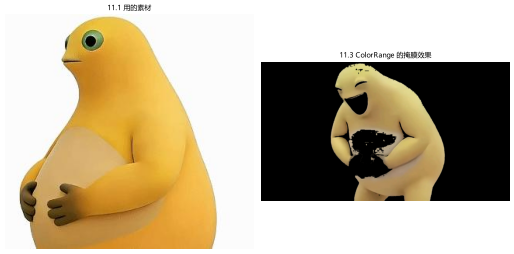

In [14]:
print('=== 11.1 Timer 类 ===')
import time


class Timer:
    def start(self):
        self._t0 = time.perf_counter()
        return self

    def stop(self):
        self._elapsed = time.perf_counter() - self._t0
        return self._elapsed

    def elapsed(self):
        return self._elapsed


t = Timer().start()
side_img = cv2.imread('res/nl_side.png')
for _ in range(2000):
    cv2.blur(side_img, (7, 7))
print(f'  2000 次 7x7 均值滤波耗时 {t.stop()*1000:.0f} ms')

print()
print('=== 11.3 ColorRange 类 ===')


class ColorRange:
    def __init__(self, lower, upper):
        self.__lower = np.array(lower)          # 私有：不给外部乱改
        self.__upper = np.array(upper)

    def mask(self, hsv):
        return cv2.inRange(hsv, self.__lower, self.__upper)


cr = ColorRange([15, 60, 120], [40, 255, 255])
hsv_hd = cv2.cvtColor(cv2.imread('res/nl_hd01.jpg'), cv2.COLOR_BGR2HSV_FULL)
m = cr.mask(hsv_hd)
print(f'  掩膜前景像素 = {int(cv2.countNonZero(m))}')

print()
print('=== 11.5 私有属性真的不可访问吗？ ===')
print('  __lower 在运行时叫 _ColorRange__lower：')
print('  cr._ColorRange__lower =', cr._ColorRange__lower.tolist(), ' <- 照样读得到')
cr._ColorRange__lower = np.array([0, 0, 0])
print('  改掉之后掩膜像素 =', int(cv2.countNonZero(cr.mask(hsv_hd))), ' <- 说明 __ 只是"约定"，不是封锁')

print()
print('=== 11.2 Camera 类（本机无摄像头，未实测）===')
cam_src = """
class Camera:
    def __init__(self, index=0):
        self.cap = cv2.VideoCapture(index)
        if not self.cap.isOpened():
            raise RuntimeError('打不开摄像头 ' + str(index))

    def read(self):
        try:
            ok, frame = self.cap.read()
            return frame if ok else None
        except Exception as e:
            print('读帧出错，跳过：', e)
            return None

    def release(self):
        self.cap.release()
"""
print(cam_src)
print('  用法：frame = cam.read()，返回 None 就跳过；release() 放 finally 里')

show_img(side_img, cv2.bitwise_and(cv2.imread('res/nl_hd01.jpg'),
                                   cv2.imread('res/nl_hd01.jpg'), mask=m),
         titles=['11.1 用的素材', '11.3 ColorRange 的掩膜效果'])

---
# 第 12 章 综合实战：红绿灯识别

**练习 1（`min_area` 改 5000）**：**没有变化** —— 亮灯的像素数是 **6361**，
  `5000 < 6361` 所以照旧画框。要看到变化，门槛必须**超过亮灯本身的像素数**：
  `min_area=7000` 时画框数变 0（但"哪个颜色像素最多"的判定**不受影响**）。
  → **调阈值之前先把实际数值打出来**，别盲改。

**练习 2（`set_roi`）**：ROI 之后**所有返回的坐标都要加回偏移 `(ox, oy)`**，
  否则外面拿到的坐标画到原图上会全错位。

**练习 3（`from_config`）**：`@classmethod` 第一个参数是 **`cls`**，
  在方法里 `return cls(...)` —— 子类调用时会构造出子类实例。
  ⚠️ 私有属性在类外要写改名后的 `_类名__ranges`；
  **更干净的做法**是让 `__init__` 接收 `ranges` 参数、`from_config` 只负责读文件。

**练习 4（视频）**：`nl_video.mp4` = 596 帧 / 25fps / 23.84 秒 / 1280×720。
  ⚠️ `VideoWriter` 的 `frameSize` 是 **`(宽, 高)`**，写错**不报错**、
  只会静默生成 0 字节文件；`try/except` 要包住**每一帧**；`release()` 忘了写视频打不开。

**练习 5（思考）**：加"**不确定**"分支（前两名像素数差距不到 30% 就判不确定）。
  红黄接近通常意味着红黄都亮 / 颜色被光照带偏 / 阈值重叠 ——
  **把不确定性显式暴露出去**交给上层（连续几帧都判红才走 / 不确定就减速），
  这比调阈值重要得多。

=== 12 红绿灯识别：min_area 的影响 ===
  min_area=  100: red->红(框1)  yellow->黄(框1)  green->绿(框1)
  min_area= 5000: red->红(框1)  yellow->黄(框1)  green->绿(框1)
  min_area= 7000: red->红(框0)  yellow->黄(框0)  green->绿(框0)
  ↑ min_area=5000 没变化（亮灯像素 6361 > 5000）；7000 就不画框了，但颜色判定不变

=== 12.2 set_roi 之后坐标要加回偏移 ===
  全图检测  : [(36, 26, 89, 89)]
  ROI 内部  : [(36, 26, 89, 89)] <- 返回的仍是原图坐标（已加回偏移）
  错开 ROI  : [] <- 红灯在上半部分，所以空了

=== 12.3 from_config 从 JSON 读阈值 ===
  配置文件内容：
{
  "min_area": 100,
  "morph_size": 5,
  "ranges": {
    "红": [
      [
        [
          0,
          100,
          100
        ],
        [
          10,
          255,
          255
        ]
      ],
      [
        [
          170,
          100,
          100
        ],
        [
          179,
          255,
          255
        ]
      ]
    ]
  }
}
  ↑ 注意 obj._TrafficLightDetector__ranges —— 私有属性只是改名，不是封锁（第 11 章练习 5）
  更干净的做法：让 __init__ 接收 ranges 参数，from_config 只负责读文件

=== 12.4 视频流水线 ===
  1280x720  25.0fps  596 帧
  VideoWriter

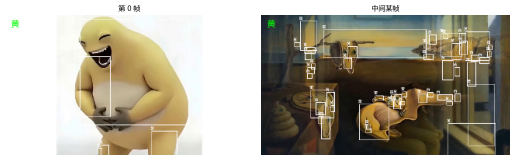

In [15]:
print('=== 12 红绿灯识别：min_area 的影响 ===')


def make_traffic_light(lit='red'):
    im = np.full((360, 160, 3), 40, np.uint8)
    cv2.rectangle(im, (10, 10), (150, 350), (25, 25, 25), -1)
    cv2.rectangle(im, (10, 10), (150, 350), (90, 90, 90), 3)
    for nm, (col, cy) in {'red': ((0, 0, 255), 70), 'yellow': ((0, 255, 255), 180),
                          'green': ((0, 255, 0), 290)}.items():
        cv2.circle(im, (80, cy), 45, col if nm == lit else (60, 60, 60), -1)
    return im


class TrafficLightDetector:
    def __init__(self, min_area=100, morph_size=5):
        self.min_area = min_area
        self.__ranges = {
            '红': [((0, 100, 100), (10, 255, 255)), ((170, 100, 100), (179, 255, 255))],
            '黄': [((20, 100, 100), (35, 255, 255))],
            '绿': [((40, 100, 100), (90, 255, 255))],
        }
        self.__kernel = np.ones((morph_size, morph_size), np.uint8)
        self._roi = None

    def set_roi(self, x, y, w, h):
        self._roi = None if x is None else (x, y, w, h)

    def masks(self, img, ox=0, oy=0):
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        out = {}
        for name, ranges in self.__ranges.items():
            m = None
            for lo, hi in ranges:
                cur = cv2.inRange(hsv, np.array(lo), np.array(hi))
                m = cur if m is None else (m | cur)
            out[name] = cv2.morphologyEx(m, cv2.MORPH_OPEN, self.__kernel)
        return out

    def detect(self, img):
        if self._roi is None:
            sub, ox, oy = img, 0, 0
        else:
            x, y, w, h = self._roi
            sub, ox, oy = img[y:y+h, x:x+w], x, y
        masks = self.masks(sub)
        areas = {n: int(cv2.countNonZero(m)) for n, m in masks.items()}
        color = max(areas, key=areas.get)
        result = img.copy()
        boxes = []
        if areas[color] >= self.min_area:
            cons, _ = cv2.findContours(masks[color], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for c in cons:
                if cv2.contourArea(c) > self.min_area:
                    bx, by, bw, bh = cv2.boundingRect(c)          # 局部坐标
                    bx, by = bx + ox, by + oy                      # ← 加回偏移！
                    boxes.append((bx, by, bw, bh))
                    cv2.rectangle(result, (bx - 5, by - 5), (bx + bw + 5, by + bh + 5),
                                  (255, 255, 255), 2)
                    cv2.putText(result, color, (bx - 12, by - 12),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
        return color, areas, boxes, result


for ma in [100, 5000, 7000]:
    det = TrafficLightDetector(min_area=ma)
    line = []
    for lit in ['red', 'yellow', 'green']:
        color, areas, boxes, _ = det.detect(make_traffic_light(lit))
        line.append(f'{lit}->{color}(框{len(boxes)})')
    print(f'  min_area={ma:5d}: ' + '  '.join(line))
print('  ↑ min_area=5000 没变化（亮灯像素 6361 > 5000）；7000 就不画框了，但颜色判定不变')

print()
print('=== 12.2 set_roi 之后坐标要加回偏移 ===')
det = TrafficLightDetector(min_area=100)
img = make_traffic_light('red')
print('  全图检测  :', det.detect(img)[2])
det.set_roi(0, 0, 160, 180)                 # 只看上半部分
print('  ROI 内部  :', det.detect(img)[2], '<- 返回的仍是原图坐标（已加回偏移）')
det.set_roi(0, 180, 160, 180)               # 只看下半部分（红灯不在里面）
print('  错开 ROI  :', det.detect(img)[2], '<- 红灯在上半部分，所以空了')

print()
print('=== 12.3 from_config 从 JSON 读阈值 ===')
import json
cfg = {'min_area': 100, 'morph_size': 5,
       'ranges': {'红': [[[0, 100, 100], [10, 255, 255]], [[170, 100, 100], [179, 255, 255]]]}}
print('  配置文件内容：')
print(json.dumps(cfg, ensure_ascii=False, indent=2))


class ConfigurableDetector(TrafficLightDetector):
    @classmethod
    def from_config(cls, path):
        with open(path, encoding='utf-8') as fh:
            c = json.load(fh)
        obj = cls(min_area=c.get('min_area', 100), morph_size=c.get('morph_size', 5))
        if 'ranges' in c:
            obj._TrafficLightDetector__ranges = {
                k: [(tuple(lo), tuple(hi)) for lo, hi in v] for k, v in c['ranges'].items()
            }
        return obj


print('  ↑ 注意 obj._TrafficLightDetector__ranges —— 私有属性只是改名，不是封锁（第 11 章练习 5）')
print('  更干净的做法：让 __init__ 接收 ranges 参数，from_config 只负责读文件')

print()
print('=== 12.4 视频流水线 ===')
cap = cv2.VideoCapture('res/nl_video.mp4')
fps = cap.get(cv2.CAP_PROP_FPS)
vw = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
vh = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f'  {vw}x{vh}  {fps}fps  {total} 帧')
# 真正存视频的写法（学生本机可以存；这里只演示流程并统计）
import os
os.makedirs('out', exist_ok=True)   # out/ 被 .gitignore 排除，新克隆下来没有这个目录，得先自己建
writer = cv2.VideoWriter('out/traffic_result.avi', cv2.VideoWriter_fourcc(*'XVID'), fps, (vw, vh))
print('  VideoWriter.isOpened() =', writer.isOpened(), f'（frameSize 必须是 (宽, 高) = ({vw}, {vh})）')
det = TrafficLightDetector(min_area=100)
hit, n, frames_vis = 0, 0, []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    try:
        color, areas, boxes, vis = det.detect(frame)
        cv2.putText(vis, color, (30, 60), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 255, 0), 3)
    except Exception as e:                                  # 出错就跳过这一帧
        print('  跳过一帧：', e)
        vis = frame
    if writer.isOpened():
        writer.write(vis)
    if len(boxes) > 0:
        hit += 1
    if n in (0, total // 2):
        frames_vis.append(cv2.resize(vis, (vw // 4, vh // 4)))
    n += 1
cap.release()
writer.release()
print(f'  处理帧数={n}  有检出帧数={hit}  命中率={100*hit/n:.1f}%')
print('  ⚠️ 这段视频是实拍场景（不是红绿灯），所以命中率不代表算法好坏，只看流程跑通')
if frames_vis:
    show_img(*frames_vis, titles=['第 0 帧', '中间某帧'])

---
# 自查清单

跑完上面这些之后，问自己几个问题：

- [ ] 每段代码**都真的跑过**了吗？还是"看着对"就跳过了？
- [ ] 遇到报错时，**先看报错信息里的函数名**（`cvtColor`? `findContours`? `adaptiveThreshold`?），
      再回去找对应那一行 —— 这比从头读代码快得多；
- [ ] 调参时有没有**先把实际数值打印出来**，还是凭感觉改数字？
- [ ] 结果不对时，有没有把**中间结果（掩膜 / 灰度图）显示出来看一眼**？
- [ ] 有没有用**第 10 章的坐标网格**确认过自己取的坐标？

## 如果实测数字和我差很多，先查这两件事

1. **图片路径对不对** —— `cv2.imread` 读不到文件**不报错，只返回 `None`**，
   后面就会莫名其妙地报 `'NoneType' object has no attribute 'shape'`；
2. **有没有漏掉 `COLOR_BGR2HSV_FULL`** —— 用成 `COLOR_BGR2HSV` 的话 H 全部错位，
   阈值区间全都对不上。

> 这两条能解释新手 80% 的"我这结果怎么和教材不一样"。